In [1]:
#packages
import pandas as pd
import numpy as np

#visual packages
import matplotlib.pyplot as plt
import seaborn as sns



In [2]:

#only using the cols mentioned
ratings_cols = ['user_id', 'recipe_id', 'rating']
ratings = pd.read_csv('RAW_interactions.csv', usecols=ratings_cols)

recipes_cols = ['id', 'name', 'tags', 'ingredients', 'n_ingredients']
recipes = pd.read_csv('RAW_recipes.csv', usecols=recipes_cols)

#print(ratings.head())
#print(recipes.head())
#
#print(ratings.shape)
#print(recipes.shape)
#
#print(ratings.dtypes)
#print(recipes.dtypes)

#print(ratings.describe())
#print(recipes.describe())



In [3]:
#remove 0 ratings
ratings = ratings[ratings['rating'] >= 1]
ratings = ratings.dropna().reset_index(drop=True)
assert ratings['rating'].between(1, 5).all()

ratings.head()


,user_id,recipe_id,rating
0,38094,40893,4
1,1293707,40893,5
2,8937,44394,4
3,126440,85009,5
4,57222,85009,5


In [4]:
print("ratings: ", len(ratings))
print("users: ", ratings['user_id'].nunique())
print("recipes:", ratings['recipe_id'].nunique())

ratings:  1071520
users:  196098
recipes: 226590


In [5]:
percent = 0.95

#ratings per recipe
recipe_count = ratings.groupby(['recipe_id'])['rating'].count().reset_index(name='count')

#only the 5% most rated
m = recipe_count['count'].quantile(percent)
q_recipes = recipe_count.copy().loc[recipe_count['count']>= m]

ratings = ratings[ratings['recipe_id'].isin(q_recipes['recipe_id'])]

print("min rating per recipe", m)
print("ratings now", len(ratings))
print("users now: ", ratings['user_id'].nunique())
print("recipes now", ratings['recipe_id'].nunique())

min rating per recipe 14.0
ratings now 473314
users now:  121994
recipes now 12487


In [6]:
#average rating with decending

recipe_avg_ratings = ratings.groupby(['recipe_id'])['rating'].mean().reset_index()
#recipe_avg_ratings
#recipe_avg_ratings.sort_values(by=['rating'], ascending=False)

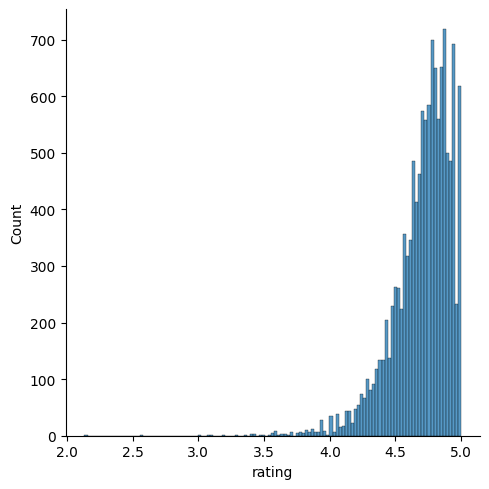

In [7]:
sns.displot(recipe_avg_ratings, x="rating")

In [8]:
#size of the two main tables
print("Ratings shape:", ratings.shape)
print("Recipies shape:", recipes.shape, "\n")

num_users = ratings['user_id'].nunique()
num_recipies = ratings['recipe_id'].nunique()
num_ratings = len(ratings)

print("Number of users:", num_users)
print("Number of recipies rated:", num_recipies, "\n")

#data density and sparsity
total_possible_ratings = num_users * num_recipies

density = num_ratings / total_possible_ratings
sparsity = 1 - density

print("number of ratings:", num_ratings)
print("Data density: {:.4%}".format(density))
print("Data sparsity: {:.4%}".format(sparsity))

Ratings shape: (473314, 3)
Recipies shape: (231637, 5) 

Number of users: 121994
Number of recipies rated: 12487 

number of ratings: 473314
Data density: 0.0311%
Data sparsity: 99.9689%


In [9]:
#only recipes left in ratings
recipes = recipes[recipes['id'].isin(ratings['recipe_id'])]
print(recipes.shape)

#save cleaned data
ratings.to_csv('ratings_clean.csv', index=False)
recipes.to_csv('recipes_clean.csv', index=False)

(12487, 5)
